
# Bayesian analysis with nested sampling

A demonstration of a Bayesian analysis using the nested sampling technique.


## Context

### 1. Bayesian analysis

Bayesian inference uses prior knowledge, in the form of a prior
distribution, in order to estimate posterior probabilities which we
traditionally visualise in the form of corner plots. These distributions
contain more information than a maximum likelihood fit as they reveal not
only the “best model” but provide a more accurate representation of errors and
correlation between parameters. In particular, non-Gaussian degeneracies are
complex to estimate with a maximum likelihood approach.

### 2. Limitations of the Markov Chain Monte Carlo approach

A well-known approach to estimate this posterior distribution is the
Markov Chain Monte Carlo (MCMC). This uses an ensemble of walkers to
produce a chain of samples that after a convergence period will reach a
stationary state. *Once convergence* is reached, the successive elements
of the chain are samples of the target posterior distribution. However,
the weakness of the MCMC approach lies in the "*Once convergence*" part.
If the walkers are started far from the best likelihood region, the convergence time can be
long or never reached if the walkers fall in a local minima. The choice
of the initialisation point can become critical for complex models with
a high number of dimensions and the ability of these walkers to escape a
local minimum or to accurately describe a complex likelihood space is
not guaranteed.

### 3. Nested sampling approach

To overcome these issues, the nested sampling (NS) algorithm has
gained traction in physics and astronomy. It is a Monte Carlo
algorithm for computing an integral of the likelihood function over
the prior model parameter space introduced in
[Skilling, 2004](https://ui.adsabs.harvard.edu/abs/2004AIPC..735..395S)_.
The method performs this integral by evolving a collection of points
through the parameter space (see recent reviews from [Ashton et al.,
2022](https://ui.adsabs.harvard.edu/abs/2022NRvMP...2...39A)_, and
[Buchner, 2023](http://arxiv.org/abs/2101.09675)_). Without going
into too many details, one important specificity of the NS method is
that it starts from the entire parameter space and evolves a
collection of live points to map all minima (including multiple modes
if any), whereas Markov Chain Monte Carlo methods require an
initialisation point and the walkers will explore the local
likelihood. The ability of these walkers to escape a local minimum or
to accurately describe a complex likelihood space is not guaranteed.
This is a fundamental difference with MCMC or Minuit which will
only ever probe the vicinity along their minimisation paths and do not
have an overview of the global likelihood landscape. The analysis
using the NS framework is more CPU time consuming than a standard
classical fit, but it provides the full posterior distribution for all
parameters, which is out of reach with traditional fitting techniques
(N*(N-1)/2 contour plots to generate). In addition, it is more robust
to the choice of initialisation, requires less human intervention and
is therefore readily integrated in pipeline analysis. In Gammapy, we
used the NS implementation of the UltraNest package
(see [here](https://johannesbuchner.github.io/UltraNest/)_ for more information), one of the
leading package in Astronomy (already used in Cosmology and in
X-rays).
For a nice visualisation of the NS method see here : [sampling
visualisation](https://johannesbuchner.github.io/UltraNest/method.html#visualisation)_.
And for a tutorial of UltraNest applied to X-ray fitting with concrete examples and questions see : [BXA
Tutorial](https://peterboorman.com/tutorial_bxa.html)_.


**Note: please cite UltraNest if used for a paper**

If you are using the "UltraNest" library for a paper, please follow its citation scheme:
[Cite UltraNest](https://johannesbuchner.github.io/UltraNest/issues.html#how-should-i-cite-ultranest)_.





## Proposed approach

In this example, we will perform a Bayesian analysis with multiple 1D
spectra of the Crab nebula data and investigate their posterior
distributions.




## Setup

As usual, we’ll start with some setup …




In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from gammapy.datasets import Datasets
from gammapy.datasets import SpectrumDatasetOnOff

from gammapy.modeling.models import (
    SkyModel,
    UniformPrior,
    LogUniformPrior,
)

from gammapy.modeling import Fit, Sampler, Parameter

/Users/qremy/anaconda3/envs/gpy-dev12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Loading the spectral datasets

Here we will load a few Crab 1D spectral data for which we will do a
fit.




In [2]:
path = "$GAMMAPY_DATA/joint-crab/spectra/hess/"

datasets = Datasets()
for id in ["23526", "23559", "23592"]:
    dataset = SpectrumDatasetOnOff.read(f"{path}pha_obs{id}.fits")
    datasets.append(dataset)

## Model definition

Now we want to define the spectral model that will be fitted to the
data.
The Crab spectra will be fitted here with a simple powerlaw for
simplicity.




In [3]:
model = SkyModel.create(spectral_model="pl", name="crab")

.. WARNING:: Priors definition:
   Unlike a traditional fit where priors on the
   parameters are optional, here it is inherent to the Bayesian approach and
   are therefore mandatory.

In this case we will set (min,max) prior that will define the
boundaries in which the sampling will be performed.
Note that it is usually recommended to use a `~gammapy.modeling.models.LogUniformPrior` for
the parameters that have a large amplitude range like the
``amplitude`` parameter.
A `~gammapy.modeling.models.UniformPrior` means that the samples will be drawn with uniform
probability between the (min,max) values in the linear or log space
in the case of a `~gammapy.modeling.models.LogUniformPrior`.




In [4]:
model.spectral_model.amplitude.prior = LogUniformPrior(min=1e-12, max=1e-10)
model.spectral_model.index.prior = UniformPrior(min=1, max=5)
datasets.models = [model]
print(datasets.models)

DatasetModels

Component 0: SkyModel

  Name                      : crab
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      2.000   +/-    0.00             
    amplitude                     :   1.00e-12   +/- 0.0e+00 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         




## Defining the sampler and options

As for the `~gammapy.modeling.Fit` object, the `~gammapy.modeling.Sampler` object can receive
different backend (although just one is available for now).
The `~gammapy.modeling.Sampler` comes with “reasonable” default parameters, but you can
change them via the ``sampler_opts`` dictionary.
Here is a short description of the most relevant parameters that you
could change :

-  ``live_points``: minimum number of live points throughout the run.
   More points allow to discover multiple peaks if existing, but is
   slower. To test the Prior boundaries and for debugging, a lower
   number (~100) can be used before a production run with more points
   (~400 or more).
-  ``frac_remain``: the cut-off condition for the integration, set by the maximum
   allowed fraction of posterior mass left in the live points vs the dead points. High
   values (e.g., 0.5) are faster and can be used if the posterior
   distribution is a relatively simple shape. A low value (1e-1, 1e-2)
   is optimal for finding peaks, but slower.
-  ``log_dir``: directory where the output files will be stored.
   If set to None, no files will be written. If set to a string, a directory
   will be created containing the ongoing status of the run and final results.
   For time consuming analysis, it is highly recommended to use that option to monitor
   the run and restart it in case of a crash (with ``resume=True``).

**Important note:** unlike the MCMC method, you don’t need to define the
number of steps for which the sampler will run. The algorithm will
automatically stop once a convergence criteria has been reached.




In [5]:
sampler_opts = {
    "live_points": 300,
    "frac_remain": 0.3,
    "log_dir": None,
}

sampler = Sampler(backend="ultranest", sampler_opts=sampler_opts)

Next we can run the sampler on a given dataset.
No options are accepted in the run method.




In [6]:
result_joint = sampler.run(datasets)

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-6e+01   [-59.1027..-59.1019]*| it/evals=2190/3360 eff=71.5686% N=300   
[ultranest] Likelihood function evaluations: 3392
[ultranest]   logZ = -65.1 +- 0.09145
[ultranest] Effective samples strategy satisfied (ESS = 998.7, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.06 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.28, need <0.5)
[ultranest]   logZ error budget: single: 0.13 bs:0.09 tail:0.26 total:0.28 required:<0.50
[ultranest] done iterating.

logZ = -65.075 +- 0.308
  single instance: logZ = -65.075 +- 0.133
  bootstrapped   : logZ = -65.097 +- 0.163
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    index               : 2.360 │ ▁ ▁▁▁▁▁▁▁▂▂▄▃▄▆▆▇▆▇▇▆▅▅▃▄▃▂▂▂▁▁▁▁▁▁▁▁ │2.975     2.670 +- 0.084
    amplitude           : 0.0000000000330│ ▁▁▁▁▁▁▁▁▁▂▃▃▄▅▆▆▇▇▆▅▆▅▄▄▄▃▂▂▁▁▁▁▁▁ ▁▁ │0.0000000000561    0.0000000000443 +- 0.0000000000030

## Understanding the outputs

In the Jupyter notebook, you should be able to see an interactive
visualisation of how the parameter space shrinks which starts from the
(min,max) shrinks down towards the optimal parameters.

The output above is filled with interesting information. Here we
provide a short description of the most relevant information provided
above.
For more detailed information see the [UltraNest
docs](https://johannesbuchner.github.io/UltraNest/issues.html#what-does-the-status-line-mean)_.

**During the sampling**

``Z=-68.8(0.53%) | Like=-63.96..-58.75 [-63.9570..-63.9539]*| it/evals=640/1068 eff=73.7327% N=300``

Some important information here is:

-  Progress (0.53%): the completed fraction of the integral. This is not a time progress bar.
   Stays at zero for a good fraction of the run.

-  Efficiency (eff value) of the sampling: this indicates out of the proposed new points,
   how many were accepted. If your efficiency is too small (<<1%), maybe
   you should revise your priors (e.g use a LogUniform prior for the
   normalisation).

**Final outputs**

The final lines indicate that all three “convergence” strategies are
satisfied (samples, posterior uncertainty, and evidence uncertainty).

``logZ = -65.104 +- 0.292``

The main goal of the Nested sampling algorithm is to estimate Z (the
Bayesian evidence) which is given above together with an uncertainty.
In a similar way to deltaLogLike and deltaAIC, deltaLogZ values can be
used for model comparison.
For more information see : [on the use of the evidence for model comparison](https://ned.ipac.caltech.edu/level5/Sept13/Trotta/Trotta4.html)_.
An interesting comparison of the efficiency and false discovery rate of
model selection with deltaLogLike and deltaLogZ is given in Appendix C of
[Buchner et al., 2014](https://ui.adsabs.harvard.edu/abs/2014A%26A...564A.125B)_.

**Results stored on disk**

if ``log_dir`` is set to a name where the results will be stored, then
a directory is created containing many useful results and plots.
A description of these outputs is given in the [Ultranest
docs](https://johannesbuchner.github.io/UltraNest/performance.html#output-files)_.




## Results




Within a Bayesian analysis, the concept of best-fit has to be viewed
differently from what is done in a gradient descent fit.

The output of the Bayesian analysis is the posterior distribution and
there is no “best-fit” output.
One has to define, based on the posteriors, what we want to consider
as “best-fit” and several options are possible:

-  the mean of the distribution
-  the median
-  the lowest likelihood value

By default the `~gammapy.modeling.models.DatasetModels` will be updated with the ``mean`` of
the posterior distributions.




In [7]:
print(result_joint.models)

DatasetModels

Component 0: SkyModel

  Name                      : crab
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      2.670   +/-    0.08             
    amplitude                     :   4.43e-11   +/- 3.0e-12 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         




The `~gammapy.modeling.Sampler` class returns a very rich dictionary.
The most “standard” information about the posterior distributions can
be found in :




In [8]:
print(result_joint.sampler_results["posterior"])

{'mean': [2.6699968318253515, 4.432460265260801e-11], 'stdev': [0.08376044670106367, 3.0033689550428276e-12], 'median': [2.667397703073262, 4.4126996627317296e-11], 'errlo': [2.589548297130687, 4.142018833029785e-11], 'errup': [2.7563376586125052, 4.7473793876783536e-11], 'information_gain_bits': [2.7024126220146494, 3.117585694355439]}


Besides mean, errors, etc, an interesting value is the
``information gain`` which estimates how much the posterior
distribution has shrunk with respect to the prior (i.e. how much
we’ve learned). A value < 1 means that the parameter is poorly
constrained within the prior range (we haven't learned much with respect to our prior assumption).
For a physical interpretation of the information gain see this
[example](https://arxiv.org/abs/2205.00009)_.

The `~gammapy.modeling.SamplerResult` dictionary contains also other interesting
information :




In [9]:
print(result_joint.sampler_results.keys())

dict_keys(['niter', 'logz', 'logzerr', 'logz_bs', 'logz_single', 'logzerr_tail', 'logzerr_bs', 'ess', 'H', 'Herr', 'posterior', 'weighted_samples', 'samples', 'maximum_likelihood', 'ncall', 'paramnames', 'logzerr_single', 'insertion_order_MWW_test'])


Of particular interest, the samples used in the process to approximate
the posterior distribution can be accessed via :




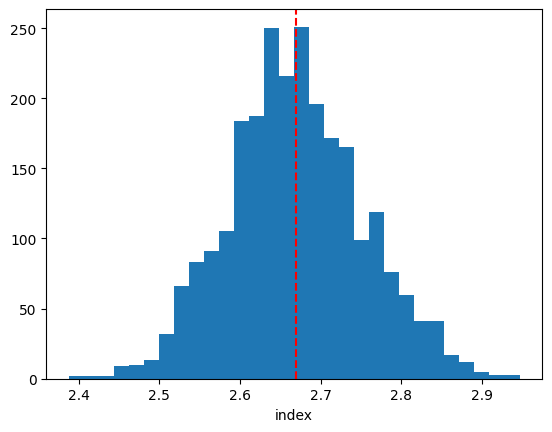

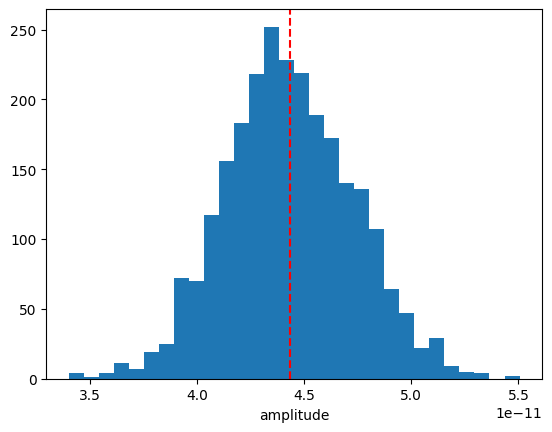

In [10]:
for i, n in enumerate(model.parameters.free_parameters.names):
    s = result_joint.samples[:, i]
    fig, ax = plt.subplots()
    ax.hist(s, bins=30)
    ax.axvline(np.mean(s), ls="--", color="red")
    ax.set_xlabel(n)
    plt.show()

While the above plots are interesting, the real strength of the Bayesian
analysis is to visualise all parameters correlations which is usually
done using “corner plots”.
Ultranest corner plot function is a wrapper around the [corner](https://corner.readthedocs.io/en/latest/api)_ package.
See the above link for optional keywords.
Other packages exist for corner plots, like
[chainconsumer](https://samreay.github.io/ChainConsumer)_ which is discussed later in this tutorial.



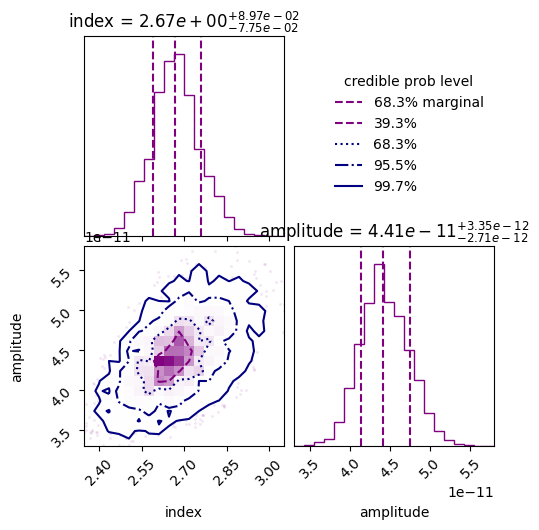

In [11]:
from ultranest.plot import cornerplot

cornerplot(
    result_joint.sampler_results,
    plot_datapoints=True,
    plot_density=True,
    bins=20,
    title_fmt=".2e",
    smooth=False,
)
plt.show()

## Spectral model error band from samples

To compute the spectral error band ("butterfly plots"), we will directly
use the samples of the posterior distribution. This is more robust as
compared to the traditional method of using the covariance matrix of
the parameters which implicitly assumes Gaussian errors while for the posterior
distribution there is no shape assumed.
This difference can become significant when the parameter errors are non-Gaussian.
For this we will need to convert the list of samples back to the spectral
model parameters with the relevant units (e.g. normalisation units).



In [12]:
def get_samples_from_posterior(spectral_model, results):
    """
    Create a list of spectral parameters with correct units
    from the unitless parameters returned by the sampler.
    """
    n_samples = results.samples.shape[0]
    samples = []
    for p in spectral_model.parameters:
        try:
            idx = spectral_model.parameters.free_unique_parameters.index(p)
            samples.append(results.samples[:, idx] * p.unit)
        except ValueError:
            samples.append(np.ones(n_samples) * p.quantity)
    return samples


samples = get_samples_from_posterior(datasets.models[0].spectral_model, result_joint)

Next we can provide these samples to the `~gammapy.modeling.models.SpectralModel.plot_error`
method.



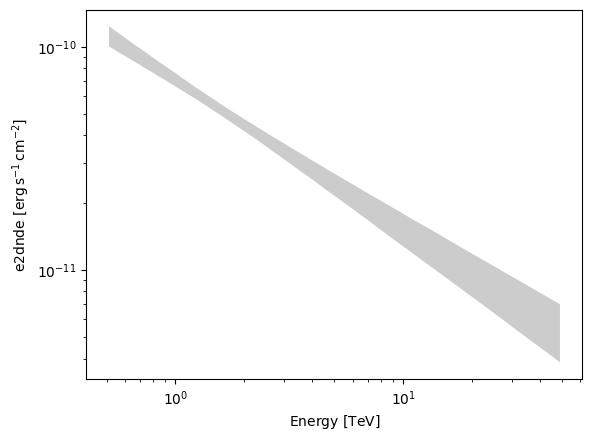

In [13]:
datasets.models[0].spectral_model.plot_error(
    energy_bounds=[0.5 * u.TeV, 50 * u.TeV], sed_type="e2dnde", samples=samples
)
plt.show()

## Highest density intervals

Given the samples, one can also compute the highest density interval (HDI)
which is also known as the smallest credible interval (SCI).
See more details [here](https://en.wikipedia.org/wiki/Credible_interval)_.
This is the smallest interval in which a given probability (e.g. 68%) is contained.

For unimodal distributions, the HDI is a single continuous interval containing
the mode whereas for multimodal distributions, the HDI can be a set of disconnected intervals.
The HDI can be particularly helpful with multimodal distributions as opposed
to the mean and quantiles approaches which will not report the important information.
Here, we showcase the HDI using the Arviz package.
Check out the many possibilities offered by [Arviz](https://python.arviz.org/)_, a package to analyze the samples posterior distributions.



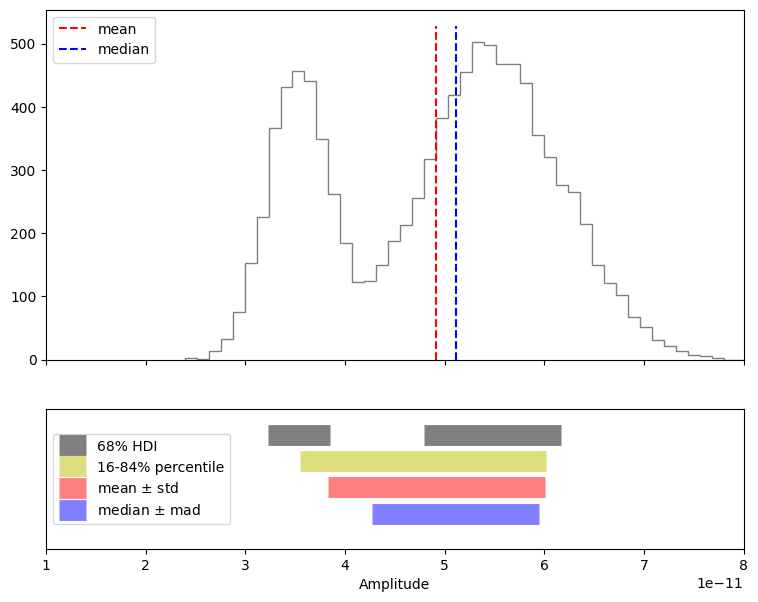

In [14]:
from arviz import hdi
import scipy.stats as stats


# Multi-modal samples example
weight = 0.3
n_samples = 10000
mu1 = 5.5e-11
sigma1 = 0.7e-11
mu2 = 3.5e-11
sigma2 = 0.3e-11
weight = 0.7
rng = np.random.default_rng(42)
component_mask = rng.uniform(size=n_samples) < weight
samples = np.empty(n_samples)
samples[component_mask] = rng.normal(mu1, sigma1, component_mask.sum())
samples[~component_mask] = rng.normal(mu2, sigma2, (~component_mask).sum())


fig, (ax1, ax2) = plt.subplots(
    2, 1, sharex=True, figsize=(9, 7), gridspec_kw={"height_ratios": [5, 2]}
)

# Highest density intervals
hdis = hdi(samples, prob=0.68, method="multimodal")
ax1.hist(
    samples,
    bins=50,
    histtype="step",
    color="k",
    alpha=0.5,
)
yl = ax1.get_ylim()

for k in range(hdis.shape[0]):
    label = "68% HDI" if k == 0 else None
    ax2.hlines(
        1 + 3 * 0.015, hdis[k, 0], hdis[k, 1], lw=15, color="k", alpha=0.5, label=label
    )

# Percentile
percentile = np.percentile(samples, q=[16, 84])
ax2.hlines(
    1 + 2 * 0.015,
    percentile[0],
    percentile[1],
    lw=15,
    color="y",
    alpha=0.5,
    label="16-84% percentile",
)

# Mean and standard deviation
mean = np.mean(samples)
std = np.std(samples)
ax1.plot([mean, mean], yl, label="mean", color="r", ls="--")
ax2.hlines(
    1 + 1 * 0.015,
    mean - std,
    mean + std,
    lw=15,
    color="r",
    alpha=0.5,
    label=r"mean $\pm$ std",
)

# Median and median absolute deviation
median = np.median(samples)
mad = stats.median_abs_deviation(samples)
ax1.plot([median, median], yl, label="median", color="b", ls="--")
ax2.hlines(
    1,
    median - mad,
    median + mad,
    lw=15,
    color="b",
    alpha=0.5,
    label=r"median $\pm$ mad",
)

ax2.legend(loc=6)
ax1.legend(loc="upper left")
ax1.set_xlim(1e-11, 8e-11)
ax2.set_ylim(0.98, 1.06)
ax2.set_xlabel("Amplitude")

ax2.tick_params(left=False, labelleft=False)

plt.show()

## Flux points compuation using sampler

This FluxCollectionEstimator estimator computes spectral flux points for a *collection of sources*
over a set of predefined energy bins. 
The operation can be performed either with the standard likelihood optimizer
(`~gammapy.modeling.Fit`) or with a sampler
(`~gammapy.modeling.Sampler`), which can be used to derive asymmetric
errors and upper limits. Default is a Sampler with options live_points=300, frac_remain=0.3.
 If the `solver` is a sampler the default prior is uniform between [-10, 10].

In [15]:
#from gammapy.estimators import FluxCollectionEstimator #in v2.2
from gammapy.estimators.points.sed import FluxCollectionEstimator

In [16]:
#FluxCollectionEstimator?

In [17]:
#for comparison we also perform the estimate with the Fit solver
estimator_fit = FluxCollectionEstimator(energy_edges=[0.5, 1, 2, 5,10,50] * u.TeV, models=datasets.models, solver=Fit())
results_fit = estimator_fit.run(datasets)

In [18]:
estimator_sampler = FluxCollectionEstimator(energy_edges=[0.5, 1, 2, 5,10,50] * u.TeV, models=datasets.models)
results = estimator_sampler.run(datasets)

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-5  39 [-5.4779..-5.4772]*| it/evals=1620/1988 eff=95.9716% N=300 0   300  
[ultranest] Likelihood function evaluations: 2017
[ultranest]   logZ = -9.72 +- 0.0869
[ultranest] Effective samples strategy satisfied (ESS = 819.2, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.08 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.28, need <0.5)
[ultranest]   logZ error budget: single: 0.12 bs:0.09 tail:0.26 total:0.28 required:<0.50
[ultranest] done iterating.

logZ = -9.710 +- 0.320
  single instance: logZ = -9.710 +- 0.115
  bootstrapped   : logZ = -9.720 +- 0.184
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    norm                : 0.53  │ ▁  ▁ ▁▁▁▁▂▃▃▃▅▇▆▇▇▆▆▅▅▆▅▃▂▂▂▁▁▁▁▁▁▁ ▁ │1.38      0.95 +- 0.11

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-6  62 [-5.7019..-5.7016]*| it/evals=1675/2050 eff=95.7143% N=300 0   0 0  
[ultranest] Likelihood function evaluations: 2052
[ultranest]   logZ = -10.04 +- 0.08701
[ultranest] Effective samples strategy satisfied (ESS = 835.3, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.07 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.28, need <0.5)
[ultranest]   logZ error budget: single: 0.12 bs:0.09 tail:0.26 total:0.28 required:<0.50
[ultranest] done iterating.

logZ = -10.037 +- 0.294
  single instance: logZ = -10.037 +- 0.116
  bootstrapped   : logZ = -10.038 +- 0.134
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    norm                : 0.70  │ ▁▁▁▁▁▁▁▂▁▂▃▃▄▅▅▅▇▆▇▅▆▄▄▄▃▃▂▁▂▁▁▁▁▁▁▁▁ │1.51      1.09 +- 0.11

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-1e+01   [-14.5811..-14.5795]*| it/evals=1541/1908 eff=95.8333% N=300  0 0 
[ultranest] Likelihood function evaluations: 1914
[ultranest]   logZ = -18.48 +- 0.08665
[ultranest] Effective samples strategy satisfied (ESS = 820.3, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.09 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.28, need <0.5)
[ultranest]   logZ error budget: single: 0.11 bs:0.09 tail:0.26 total:0.28 required:<0.50
[ultranest] done iterating.

logZ = -18.490 +- 0.337
  single instance: logZ = -18.490 +- 0.110
  bootstrapped   : logZ = -18.478 +- 0.212
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    norm                : 0.63  │ ▁  ▁▁▁▁▁▂▂▃▄▃▆▆▇▇▇▆▆▄▄▄▅▂▁▁▁▁▁▁▁▁▁▁▁▁ │1.88      1.22 +- 0.16

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-1e+01  -9.8496..-9.8489]*| it/evals=1350/1699 eff=96.4975% N=300 00  0 
[ultranest] Likelihood function evaluations: 1720
[ultranest]   logZ = -13.12 +- 0.06583
[ultranest] Effective samples strategy satisfied (ESS = 789.1, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.11 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.27, need <0.5)
[ultranest]   logZ error budget: single: 0.10 bs:0.07 tail:0.26 total:0.27 required:<0.50
[ultranest] done iterating.

logZ = -13.151 +- 0.318
  single instance: logZ = -13.151 +- 0.102
  bootstrapped   : logZ = -13.119 +- 0.180
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    norm                : 0.26  │ ▁▁▁▁▁▁▂▄▄▆▇▇▆▆▇▇▅▄▄▂▂▂▁▁▁▁▁▁▁▁▁     ▁ │2.62      1.13 +- 0.27

[ultranest] Sampling 300 live points from prior ...


[ultranest] Explored until L=-1e+01  -9.8108..-9.8107]*| it/evals=1320/1666 eff=96.6325% N=300  0 0  
[ultranest] Likelihood function evaluations: 1686
[ultranest]   logZ = -13.01 +- 0.09121
[ultranest] Effective samples strategy satisfied (ESS = 827.5, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.47+-0.13 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.28, need <0.5)
[ultranest]   logZ error budget: single: 0.10 bs:0.09 tail:0.26 total:0.28 required:<0.50
[ultranest] done iterating.

logZ = -13.008 +- 0.310
  single instance: logZ = -13.008 +- 0.099
  bootstrapped   : logZ = -13.007 +- 0.166
  tail           : logZ = +- 0.262
insert order U test : converged: True correlation: inf iterations

    norm                : -0.11 │ ▁ ▁▁▂▂▃▃▇▆▆▇▇▇▇▆▆▃▄▃▄▃▂▂▁▁▁▁▁▁▁▁▁▁▁ ▁ │2.39      0.85 +- 0.34



Results are store in a dict that contains the samples for every sources and every energy bin.

In [19]:
results.keys()

dict_keys(['energy_edges', 'solver_results', 'flux_points', 'samples'])

In [20]:
results["samples"]

{'dnde': {'crab': [<Quantity [-1.08625811e-09, -1.08193450e-09, -1.06262636e-09, ...,
               1.01651845e-10,  1.01654982e-10,  1.01718474e-10] 1 / (TeV s cm2)>,
   <Quantity [-1.68023218e-10, -1.67582148e-10, -1.65488159e-10, ...,
               1.82897061e-11,  1.82931400e-11,  1.82925644e-11] 1 / (TeV s cm2)>,
   <Quantity [-1.95763127e-11, -1.91987797e-11, -1.89727924e-11, ...,
               2.38660767e-12,  2.38688075e-12,  2.38693974e-12] 1 / (TeV s cm2)>,
   <Quantity [-2.27966229e-12, -2.25210938e-12, -2.21887367e-12, ...,
               2.45838582e-13,  2.45536253e-13,  2.45565142e-13] 1 / (TeV s cm2)>,
   <Quantity [-1.05355501e-13, -1.04445501e-13, -1.03848605e-13, ...,
               7.86039125e-15,  7.86046603e-15,  7.86147788e-15] 1 / (TeV s cm2)>]},
 'weights': [array([0.        , 0.        , 0.        , ..., 0.00102461, 0.00102461,
         0.00102461], shape=(1950,)),
  array([0.        , 0.        , 0.        , ..., 0.00102275, 0.00102275,
         0.00102275]

To visualize the results one can use a so-called violin plot.
Unlike standard error bars which only shows summary statistics,
a violin plot shows the full probability density for each energy bin.

In [21]:
from gammapy.visualization import plot_samples_violin_vs_energy

In [22]:
#plot_samples_violin_vs_energy?

/Users/qremy/Work/GitHub/gammapy/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


(2e-13, 8e-11)

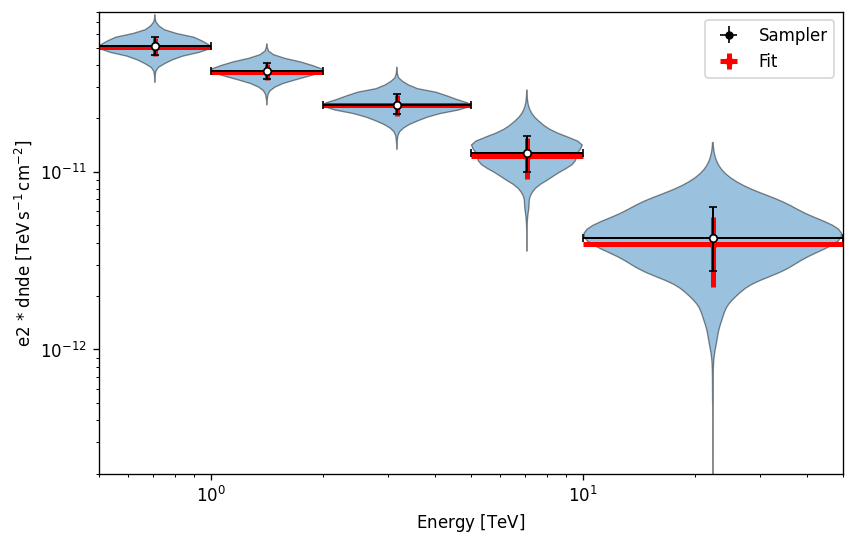

In [23]:
plt.figure(figsize=(8,5), dpi=120)
ax = plot_samples_violin_vs_energy(
    energy_edges=results['energy_edges'],
    samples_per_band = results['samples']['dnde']['crab'],
    weights_per_band = results['samples']['weights'],
    energy_power=2
)
results['flux_points']['crab'].plot(ax=ax, energy_power=2, color="k", lw=1, label="Sampler")
results_fit['flux_points']['crab'].plot(ax=ax, energy_power=2, color="r", lw=3, label="Fit")
plt.legend()
plt.ylim([2e-13, 8e-11])